<a href="https://colab.research.google.com/github/sheelathangarajan/dfu-prediction-dataset/blob/main/Assignment_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
# Force a clean mount of your Google Drive to refresh the file system paths
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F

In [ ]:
import os
import time
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

file_path = "/content/drive/MyDrive/RL Lab/cleaned_train_sentimantal_data.csv"

# Wait brief moment for virtual file system synchronization if drive was just mounted
if not os.path.exists(file_path):
    time.sleep(2)

# Verify path existence
if not os.path.exists(file_path):
    print(f"\033[91m[ERROR] File not found at: {file_path}\033[0m")
    drive_dir = "/content/drive/MyDrive"
    if os.path.exists(drive_dir):
        print("Scanning '/content/drive/MyDrive' for files matching 'sentim'...")
        found = False
        for root, dirs, files in os.walk(drive_dir):
            for file in files:
                if "sentim" in file.lower():
                    print(f"-> Found possible match at: {os.path.join(root, file)}")
                    found = True
        if not found:
            print("No matching CSV files containing 'sentim' were found in Google Drive.")
    else:
        print("Google Drive mount path is inaccessible. Please run cell '6T3W-IB1gp6d' to mount Google Drive.")
    raise FileNotFoundError(f"Could not locate {file_path}. If Google Drive was just mounted, try running this cell again in a few seconds.")

# Load dataset
df = pd.read_csv(file_path)

# Use 'cleaned_text' as input and 'sentiment' as label
texts = df['cleaned_text'].astype(str).values
labels = df['sentiment'].values

# Encode labels into integers
le = LabelEncoder()
labels = le.fit_transform(labels)

# Tokenize text
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)
seqs = tokenizer.texts_to_sequences(texts)
padded = pad_sequences(seqs, maxlen=100, padding='post', truncating='post')

# Train-Validation-Test split (70% train, 10% validation, 20% test)
X_train_full, X_test, y_train_full, y_test = train_test_split(padded, labels, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.125, random_state=42)

In [ ]:
class TextDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_data = TextDataset(X_train, y_train)
val_data = TextDataset(X_val, y_val)
test_data = TextDataset(X_test, y_test)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

In [ ]:
import torch
import torch.nn as nn

class RNN_Model(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes, model_type="rnn"):
        super(RNN_Model, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)

        if model_type == "rnn":
            self.rnn = nn.RNN(embed_dim, hidden_dim, num_layers=1, batch_first=True, nonlinearity="tanh")
        elif model_type == "lstm":
            self.rnn = nn.LSTM(embed_dim, hidden_dim, num_layers=1, batch_first=True)
        elif model_type == "gru":
            self.rnn = nn.GRU(embed_dim, hidden_dim, num_layers=1, batch_first=True)
        else:
            raise ValueError("Invalid model_type")

        bidir_factor = 2 if "bi" in model_type else 1
        self.fc = nn.Linear(hidden_dim * bidir_factor, num_classes)

    def forward(self, x):
        x = self.embedding(x)
        out, _ = self.rnn(x)
        out = out[:, -1, :]
        out = self.fc(out)
        return out

In [ ]:
def train_and_evaluate(model_type):
    # Initialize vocab_size from the tokenizer
    vocab_size = len(tokenizer.word_index) + 1
    embed_dim = 128
    hidden_dim = 128
    num_classes = len(np.unique(labels))

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = RNN_Model(vocab_size, embed_dim, hidden_dim, num_classes, model_type=model_type.lower()).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    history = []

    # Training & Validation loop
    for epoch in range(25):
        model.train()
        total_train_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            output = model(X_batch)
            loss = criterion(output, y_batch)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()

        epoch_train_loss = total_train_loss / len(train_loader)

        # Validation phase
        model.eval()
        total_val_loss = 0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                output = model(X_batch)
                loss = criterion(output, y_batch)
                total_val_loss += loss.item()
                preds = torch.argmax(output, dim=1)
                val_correct += (preds == y_batch).sum().item()
                val_total += y_batch.size(0)

        epoch_val_loss = total_val_loss / len(val_loader)
        epoch_val_acc = val_correct / val_total

        print(f"[{model_type}] Epoch {epoch+1}/25 - Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")
        history.append({
            "epoch": epoch + 1,
            "loss": epoch_train_loss,
            "val_loss": epoch_val_loss,
            "val_acc": epoch_val_acc
        })

    # Test Evaluation
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            output = model(X_batch)
            preds = torch.argmax(output, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(y_batch.numpy())

    print(f"\n==== {model_type.upper()} TEST RESULTS ====")
    accuracy = accuracy_score(all_labels, all_preds)
    print("Accuracy:", accuracy)
    print("\nClassification Report:\n", classification_report(all_labels, all_preds, target_names=le.classes_))
    print("\nConfusion Matrix:\n", confusion_matrix(all_labels, all_preds))

    return model, history

In [ ]:
# Ensure tokenizer and dataset-related variables exist before running
if 'tokenizer' not in globals() or 'train_loader' not in globals():
    print("\033[91m[ERROR] Data preprocessing variables are missing.\033[0m")
    print("Please run the data preparation cells first:")
    print("1. Run the data loading cell ('iXfA64NRp2PL') to prepare 'tokenizer'")
    print("2. Run the DataLoader cell ('Km5aChNNqKnX') to prepare 'train_loader'")
    print("3. Once those cells run successfully, execute this cell again to start training.")
else:
    architectures = ["RNN", "LSTM", "GRU"]

    models = {}
    histories = []

    for architecture in architectures:
        print(f"\n{'=' * 55}")
        print(f"Training {architecture}")
        print(f"{'=' * 55}")

        # Call the correct function name: train_and_evaluate
        model, history = train_and_evaluate(model_type=architecture)

        models[architecture] = model
        histories.append(history)


Training RNN
[RNN] Epoch 1/25 - Loss: 1.0944 | Val Loss: 1.0954 | Val Acc: 0.3119
[RNN] Epoch 2/25 - Loss: 1.0900 | Val Loss: 1.0894 | Val Acc: 0.3996
[RNN] Epoch 3/25 - Loss: 1.0898 | Val Loss: 1.0934 | Val Acc: 0.3996
[RNN] Epoch 4/25 - Loss: 1.0887 | Val Loss: 1.0889 | Val Acc: 0.3996
[RNN] Epoch 5/25 - Loss: 1.0908 | Val Loss: 1.0891 | Val Acc: 0.3996
[RNN] Epoch 6/25 - Loss: 1.0893 | Val Loss: 1.0889 | Val Acc: 0.3996
[RNN] Epoch 7/25 - Loss: 1.0886 | Val Loss: 1.0901 | Val Acc: 0.3996
[RNN] Epoch 8/25 - Loss: 1.0898 | Val Loss: 1.0915 | Val Acc: 0.3996
[RNN] Epoch 9/25 - Loss: 1.0898 | Val Loss: 1.0905 | Val Acc: 0.3996
[RNN] Epoch 10/25 - Loss: 1.0889 | Val Loss: 1.0892 | Val Acc: 0.3996
[RNN] Epoch 11/25 - Loss: 1.0889 | Val Loss: 1.0887 | Val Acc: 0.3996
[RNN] Epoch 12/25 - Loss: 1.0885 | Val Loss: 1.0890 | Val Acc: 0.3996
[RNN] Epoch 13/25 - Loss: 1.0885 | Val Loss: 1.0897 | Val Acc: 0.3996
[RNN] Epoch 14/25 - Loss: 1.0880 | Val Loss: 1.0900 | Val Acc: 0.3996
[RNN] Epoch 15/

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


[LSTM] Epoch 1/25 - Loss: 1.0886 | Val Loss: 1.0893 | Val Acc: 0.3996
[LSTM] Epoch 2/25 - Loss: 1.0874 | Val Loss: 1.0890 | Val Acc: 0.3996
[LSTM] Epoch 3/25 - Loss: 1.0869 | Val Loss: 1.0887 | Val Acc: 0.3996
[LSTM] Epoch 4/25 - Loss: 1.0869 | Val Loss: 1.0887 | Val Acc: 0.3996
[LSTM] Epoch 5/25 - Loss: 1.0869 | Val Loss: 1.0889 | Val Acc: 0.3996
[LSTM] Epoch 6/25 - Loss: 1.0871 | Val Loss: 1.0887 | Val Acc: 0.3996
[LSTM] Epoch 7/25 - Loss: 1.0867 | Val Loss: 1.0889 | Val Acc: 0.3996
[LSTM] Epoch 8/25 - Loss: 1.0869 | Val Loss: 1.0887 | Val Acc: 0.3996
[LSTM] Epoch 9/25 - Loss: 1.0868 | Val Loss: 1.0888 | Val Acc: 0.3996
[LSTM] Epoch 10/25 - Loss: 1.0868 | Val Loss: 1.0890 | Val Acc: 0.3996
[LSTM] Epoch 11/25 - Loss: 1.0868 | Val Loss: 1.0887 | Val Acc: 0.3996
[LSTM] Epoch 12/25 - Loss: 1.0868 | Val Loss: 1.0887 | Val Acc: 0.3996
[LSTM] Epoch 13/25 - Loss: 1.0868 | Val Loss: 1.0887 | Val Acc: 0.3996
[LSTM] Epoch 14/25 - Loss: 1.0868 | Val Loss: 1.0888 | Val Acc: 0.3996
[LSTM] Epoch 15

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


[GRU] Epoch 1/25 - Loss: 1.0927 | Val Loss: 1.0925 | Val Acc: 0.3996
[GRU] Epoch 2/25 - Loss: 1.0901 | Val Loss: 1.0904 | Val Acc: 0.3996
[GRU] Epoch 3/25 - Loss: 1.0887 | Val Loss: 1.0926 | Val Acc: 0.3996
[GRU] Epoch 4/25 - Loss: 1.0882 | Val Loss: 1.0903 | Val Acc: 0.3996
[GRU] Epoch 5/25 - Loss: 1.0882 | Val Loss: 1.0895 | Val Acc: 0.3996
[GRU] Epoch 6/25 - Loss: 1.0881 | Val Loss: 1.0933 | Val Acc: 0.3996
[GRU] Epoch 7/25 - Loss: 1.0886 | Val Loss: 1.0892 | Val Acc: 0.3996
[GRU] Epoch 8/25 - Loss: 1.0876 | Val Loss: 1.0901 | Val Acc: 0.3996
[GRU] Epoch 9/25 - Loss: 1.0885 | Val Loss: 1.0890 | Val Acc: 0.3996
[GRU] Epoch 10/25 - Loss: 1.0888 | Val Loss: 1.0898 | Val Acc: 0.3996
[GRU] Epoch 11/25 - Loss: 1.0883 | Val Loss: 1.0889 | Val Acc: 0.3996
[GRU] Epoch 12/25 - Loss: 1.0886 | Val Loss: 1.0898 | Val Acc: 0.3996
[GRU] Epoch 13/25 - Loss: 1.0891 | Val Loss: 1.0897 | Val Acc: 0.3996
[GRU] Epoch 14/25 - Loss: 1.0878 | Val Loss: 1.0942 | Val Acc: 0.3996
[GRU] Epoch 15/25 - Loss: 1.0

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
for model_type in ["rnn", "lstm", "gru"]:
    train_and_evaluate(model_type)


[rnn] Epoch 1/25 - Loss: 1.0933 | Val Loss: 1.0943 | Val Acc: 0.3996
[rnn] Epoch 2/25 - Loss: 1.0911 | Val Loss: 1.0973 | Val Acc: 0.3996
[rnn] Epoch 3/25 - Loss: 1.0890 | Val Loss: 1.0937 | Val Acc: 0.3996
[rnn] Epoch 4/25 - Loss: 1.0902 | Val Loss: 1.0903 | Val Acc: 0.3996
[rnn] Epoch 5/25 - Loss: 1.0889 | Val Loss: 1.0907 | Val Acc: 0.3996
[rnn] Epoch 6/25 - Loss: 1.0888 | Val Loss: 1.0920 | Val Acc: 0.3996
[rnn] Epoch 7/25 - Loss: 1.0891 | Val Loss: 1.0892 | Val Acc: 0.3996
[rnn] Epoch 8/25 - Loss: 1.0883 | Val Loss: 1.0963 | Val Acc: 0.3996
[rnn] Epoch 9/25 - Loss: 1.0920 | Val Loss: 1.0992 | Val Acc: 0.3996
[rnn] Epoch 10/25 - Loss: 1.0949 | Val Loss: 1.0937 | Val Acc: 0.3996
[rnn] Epoch 11/25 - Loss: 1.0920 | Val Loss: 1.1035 | Val Acc: 0.3996
[rnn] Epoch 12/25 - Loss: 1.0918 | Val Loss: 1.0968 | Val Acc: 0.3996
[rnn] Epoch 13/25 - Loss: 1.0919 | Val Loss: 1.0928 | Val Acc: 0.3996
[rnn] Epoch 14/25 - Loss: 1.0915 | Val Loss: 1.0941 | Val Acc: 0.3996
[rnn] Epoch 15/25 - Loss: 1.0

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


[lstm] Epoch 1/25 - Loss: 1.0888 | Val Loss: 1.0892 | Val Acc: 0.3996
[lstm] Epoch 2/25 - Loss: 1.0872 | Val Loss: 1.0887 | Val Acc: 0.3996
[lstm] Epoch 3/25 - Loss: 1.0870 | Val Loss: 1.0887 | Val Acc: 0.3996
[lstm] Epoch 4/25 - Loss: 1.0869 | Val Loss: 1.0888 | Val Acc: 0.3996
[lstm] Epoch 5/25 - Loss: 1.0871 | Val Loss: 1.0888 | Val Acc: 0.3996
[lstm] Epoch 6/25 - Loss: 1.0869 | Val Loss: 1.0889 | Val Acc: 0.3996
[lstm] Epoch 7/25 - Loss: 1.0867 | Val Loss: 1.0887 | Val Acc: 0.3996
[lstm] Epoch 8/25 - Loss: 1.0870 | Val Loss: 1.0887 | Val Acc: 0.3996
[lstm] Epoch 9/25 - Loss: 1.0868 | Val Loss: 1.0890 | Val Acc: 0.3996
[lstm] Epoch 10/25 - Loss: 1.0868 | Val Loss: 1.0887 | Val Acc: 0.3996
[lstm] Epoch 11/25 - Loss: 1.0869 | Val Loss: 1.0889 | Val Acc: 0.3996
[lstm] Epoch 12/25 - Loss: 1.0869 | Val Loss: 1.0889 | Val Acc: 0.3996
[lstm] Epoch 13/25 - Loss: 1.0868 | Val Loss: 1.0886 | Val Acc: 0.3996
[lstm] Epoch 14/25 - Loss: 1.0868 | Val Loss: 1.0887 | Val Acc: 0.3996
[lstm] Epoch 15

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


[gru] Epoch 1/25 - Loss: 1.0926 | Val Loss: 1.0892 | Val Acc: 0.3996
[gru] Epoch 2/25 - Loss: 1.0904 | Val Loss: 1.1020 | Val Acc: 0.3119
[gru] Epoch 3/25 - Loss: 1.0898 | Val Loss: 1.0941 | Val Acc: 0.3996
[gru] Epoch 4/25 - Loss: 1.0901 | Val Loss: 1.0946 | Val Acc: 0.3996
[gru] Epoch 5/25 - Loss: 1.0895 | Val Loss: 1.0906 | Val Acc: 0.3996
[gru] Epoch 6/25 - Loss: 1.0897 | Val Loss: 1.0907 | Val Acc: 0.3996
[gru] Epoch 7/25 - Loss: 1.0880 | Val Loss: 1.0903 | Val Acc: 0.3996
[gru] Epoch 8/25 - Loss: 1.0887 | Val Loss: 1.0909 | Val Acc: 0.3996
[gru] Epoch 9/25 - Loss: 1.0894 | Val Loss: 1.0913 | Val Acc: 0.3996
[gru] Epoch 10/25 - Loss: 1.0884 | Val Loss: 1.0919 | Val Acc: 0.3996
[gru] Epoch 11/25 - Loss: 1.0890 | Val Loss: 1.0889 | Val Acc: 0.3996
[gru] Epoch 12/25 - Loss: 1.0900 | Val Loss: 1.0893 | Val Acc: 0.3996
[gru] Epoch 13/25 - Loss: 1.0893 | Val Loss: 1.0908 | Val Acc: 0.3996
[gru] Epoch 14/25 - Loss: 1.0885 | Val Loss: 1.0929 | Val Acc: 0.3996
[gru] Epoch 15/25 - Loss: 1.0

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Re-run training setup to ensure all variables exist in the current runtime environment
architectures = ["RNN", "LSTM", "GRU"]
models = {}
histories = []

for architecture in architectures:
    print(f"\nTraining {architecture}...")
    model, history = train_and_evaluate(model_type=architecture)
    models[architecture] = model
    histories.append(history)


Training RNN...
[RNN] Epoch 1/25 - Loss: 1.0943 | Val Loss: 1.0887 | Val Acc: 0.3996
[RNN] Epoch 2/25 - Loss: 1.0918 | Val Loss: 1.0906 | Val Acc: 0.3996
[RNN] Epoch 3/25 - Loss: 1.0906 | Val Loss: 1.0911 | Val Acc: 0.3996
[RNN] Epoch 4/25 - Loss: 1.0900 | Val Loss: 1.0898 | Val Acc: 0.3996
[RNN] Epoch 5/25 - Loss: 1.0910 | Val Loss: 1.0914 | Val Acc: 0.3996
[RNN] Epoch 6/25 - Loss: 1.0888 | Val Loss: 1.0896 | Val Acc: 0.3996
[RNN] Epoch 7/25 - Loss: 1.0896 | Val Loss: 1.0891 | Val Acc: 0.3996
[RNN] Epoch 8/25 - Loss: 1.0895 | Val Loss: 1.0902 | Val Acc: 0.3996
[RNN] Epoch 9/25 - Loss: 1.0906 | Val Loss: 1.0916 | Val Acc: 0.3996
[RNN] Epoch 10/25 - Loss: 1.0891 | Val Loss: 1.0905 | Val Acc: 0.3996
[RNN] Epoch 11/25 - Loss: 1.0903 | Val Loss: 1.0931 | Val Acc: 0.3996
[RNN] Epoch 12/25 - Loss: 1.0892 | Val Loss: 1.0893 | Val Acc: 0.3996
[RNN] Epoch 13/25 - Loss: 1.0893 | Val Loss: 1.0900 | Val Acc: 0.3996
[RNN] Epoch 14/25 - Loss: 1.0907 | Val Loss: 1.0935 | Val Acc: 0.3996
[RNN] Epoch 

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


[LSTM] Epoch 1/25 - Loss: 1.0897 | Val Loss: 1.0896 | Val Acc: 0.3996
[LSTM] Epoch 2/25 - Loss: 1.0870 | Val Loss: 1.0907 | Val Acc: 0.3996
[LSTM] Epoch 3/25 - Loss: 1.0875 | Val Loss: 1.0886 | Val Acc: 0.3996
[LSTM] Epoch 4/25 - Loss: 1.0872 | Val Loss: 1.0889 | Val Acc: 0.3996
[LSTM] Epoch 5/25 - Loss: 1.0871 | Val Loss: 1.0890 | Val Acc: 0.3996
[LSTM] Epoch 6/25 - Loss: 1.0870 | Val Loss: 1.0886 | Val Acc: 0.3996
[LSTM] Epoch 7/25 - Loss: 1.0869 | Val Loss: 1.0891 | Val Acc: 0.3996
[LSTM] Epoch 8/25 - Loss: 1.0870 | Val Loss: 1.0887 | Val Acc: 0.3996
[LSTM] Epoch 9/25 - Loss: 1.0869 | Val Loss: 1.0890 | Val Acc: 0.3996
[LSTM] Epoch 10/25 - Loss: 1.0868 | Val Loss: 1.0888 | Val Acc: 0.3996
[LSTM] Epoch 11/25 - Loss: 1.0868 | Val Loss: 1.0895 | Val Acc: 0.3996
[LSTM] Epoch 12/25 - Loss: 1.0869 | Val Loss: 1.0889 | Val Acc: 0.3996
[LSTM] Epoch 13/25 - Loss: 1.0868 | Val Loss: 1.0889 | Val Acc: 0.3996
[LSTM] Epoch 14/25 - Loss: 1.0870 | Val Loss: 1.0887 | Val Acc: 0.3996
[LSTM] Epoch 15

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


[GRU] Epoch 1/25 - Loss: 1.0932 | Val Loss: 1.0902 | Val Acc: 0.3996
[GRU] Epoch 2/25 - Loss: 1.0898 | Val Loss: 1.0900 | Val Acc: 0.3996
[GRU] Epoch 3/25 - Loss: 1.0889 | Val Loss: 1.0920 | Val Acc: 0.3996
[GRU] Epoch 4/25 - Loss: 1.0897 | Val Loss: 1.0913 | Val Acc: 0.3996
[GRU] Epoch 5/25 - Loss: 1.0886 | Val Loss: 1.0887 | Val Acc: 0.3996
[GRU] Epoch 6/25 - Loss: 1.0892 | Val Loss: 1.0902 | Val Acc: 0.3996
[GRU] Epoch 7/25 - Loss: 1.0893 | Val Loss: 1.0912 | Val Acc: 0.3996
[GRU] Epoch 8/25 - Loss: 1.0884 | Val Loss: 1.0890 | Val Acc: 0.3996
[GRU] Epoch 9/25 - Loss: 1.0884 | Val Loss: 1.0923 | Val Acc: 0.3996
[GRU] Epoch 10/25 - Loss: 1.0881 | Val Loss: 1.0888 | Val Acc: 0.3996
[GRU] Epoch 11/25 - Loss: 1.0877 | Val Loss: 1.0904 | Val Acc: 0.3996
[GRU] Epoch 12/25 - Loss: 1.0889 | Val Loss: 1.0888 | Val Acc: 0.3996
[GRU] Epoch 13/25 - Loss: 0.8871 | Val Loss: 0.7861 | Val Acc: 0.6630
[GRU] Epoch 14/25 - Loss: 0.6659 | Val Loss: 0.7760 | Val Acc: 0.6772
[GRU] Epoch 15/25 - Loss: 0.5

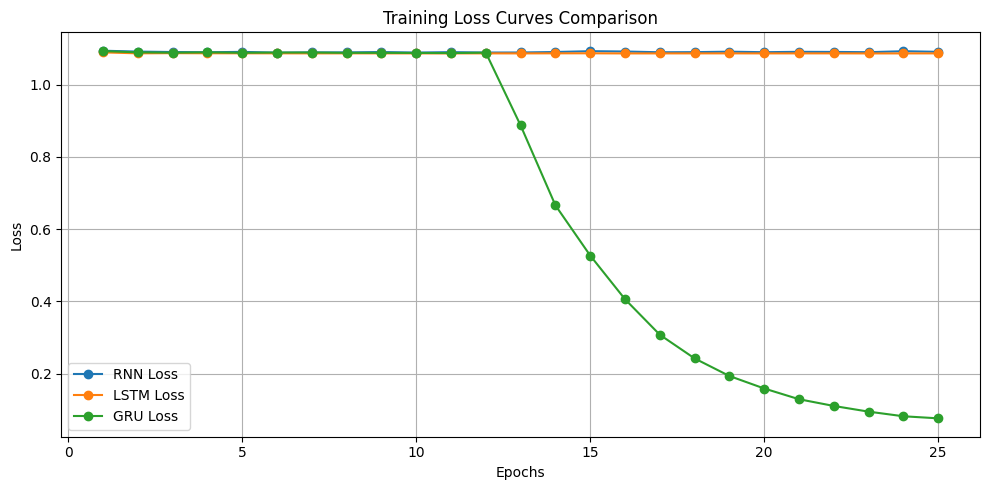

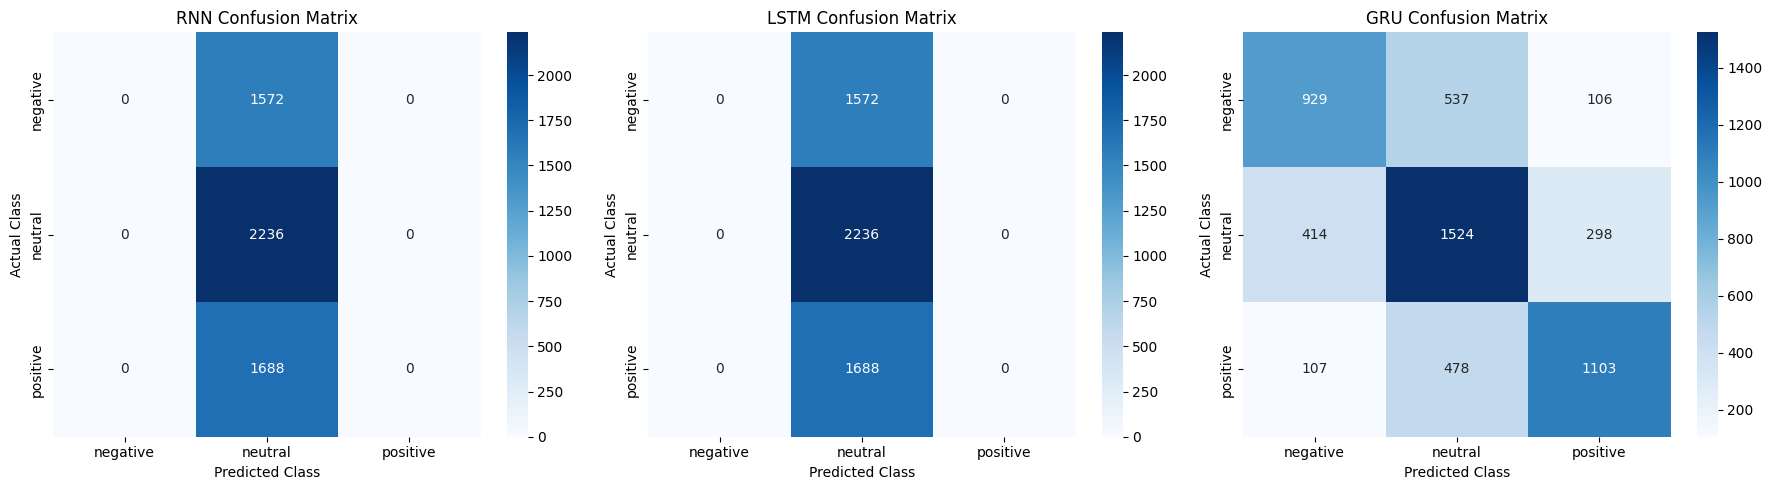

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import torch
import numpy as np

# 1. Plot Training Loss Curves for All Models
plt.figure(figsize=(10, 5))
for arch, history in zip(architectures, histories):
    epochs = [h["epoch"] for h in history]
    losses = [h["loss"] for h in history]
    plt.plot(epochs, losses, marker='o', label=f"{arch} Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Curves Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. Calculate Confusion Matrices for All Models and Store Them in a List
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
confusion_matrices = []

for arch in architectures:
    current_model = models[arch]
    current_model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            output = current_model(X_batch)
            preds = torch.argmax(output, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(y_batch.numpy())

    # Compute confusion matrix and append to list
    cm = confusion_matrix(all_labels, all_preds, labels=range(len(le.classes_)))
    confusion_matrices.append(cm)

# 3. Plot Confusion Matrices Side-by-Side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, (arch, cm) in enumerate(zip(architectures, confusion_matrices)):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=le.classes_,
                yticklabels=le.classes_,
                ax=axes[idx])
    axes[idx].set_xlabel("Predicted Class")
    axes[idx].set_ylabel("Actual Class")
    axes[idx].set_title(f"{arch} Confusion Matrix")

plt.tight_layout()
plt.show()